# Notebook 04: Proposed Model - CNN-BiLSTM-Attention
## Graduation Thesis: CNN-BiLSTM-Attention Model for Electricity Load Forecasting in a Microgrid

**Proposed Model:** CNN-BiLSTM-Attention
- CNN: Extract local features
- BiLSTM: Learn bidirectional temporal dependencies
- Attention: Focus on important time steps

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, json, joblib, warnings
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv1D, Bidirectional,
                                     LSTM, Dense, Dropout, Layer,
                                     BatchNormalization, Add, LayerNormalization)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras import regularizers
from helpers import inverse_transform_target, calculate_metrics, plot_training_history, plot_predictions

warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)

PROJECT_DIR = os.getcwd()
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

data = np.load(os.path.join(DATA_DIR, 'processed_data.npz'))
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']

with open(os.path.join(DATA_DIR, 'config.json')) as f:
    config = json.load(f)

scaler = joblib.load(os.path.join(DATA_DIR, 'scaler.pkl'))
TARGET_IDX = config['TARGET_IDX']
n_features = config['n_features']

print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')

X_train: (12115, 48, 37)
X_test: (2559, 48, 37)


## 1. Attention Layer

In [2]:
class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name='attention_weight',
                                shape=(input_shape[-1], input_shape[-1]),
                                initializer='glorot_uniform', trainable=True)
        self.b = self.add_weight(name='attention_bias',
                                shape=(input_shape[-1],),
                                initializer='zeros', trainable=True)
        self.u = self.add_weight(name='attention_context',
                                shape=(input_shape[-1],),
                                initializer='glorot_uniform', trainable=True)
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        score = tf.nn.tanh(tf.tensordot(x, self.W, axes=1) + self.b)
        attention_weights = tf.nn.softmax(tf.tensordot(score, self.u, axes=1), axis=1)
        context_vector = tf.reduce_sum(x * tf.expand_dims(attention_weights, -1), axis=1)
        return context_vector, attention_weights

    def get_config(self):
        return super(AttentionLayer, self).get_config()

print('Attention Layer defined!')

Attention Layer defined!


## 2. Build CNN-BiLSTM-Attention Model (Optimized v3)

**Improvements over v1/v2:**
- Remove MaxPooling to preserve the original temporal resolution (48 time steps)
- Use dilated convolutions to capture multi-scale temporal patterns
- Incorporate residual connections within the CNN block
- Replace Batch Normalization with Layer Normalization
- Remove dropout to reduce the risk of underfitting, given the relatively smooth data
- Replace MSE with Huber loss for greater robustness to outliers

In [3]:
def build_proposed_model(input_shape):
    inputs = Input(shape=input_shape)

    # CNN Block - dilated conv, NO pooling, residual
    c1 = Conv1D(64, kernel_size=3, activation='relu', padding='same', dilation_rate=1)(inputs)
    c1 = LayerNormalization()(c1)
    c2 = Conv1D(64, kernel_size=3, activation='relu', padding='same', dilation_rate=2)(c1)
    c2 = LayerNormalization()(c2)
    c3 = Conv1D(64, kernel_size=3, activation='relu', padding='same', dilation_rate=4)(c2)
    c3 = LayerNormalization()(c3)

    # Residual: project input to 64 dim + add
    shortcut = Conv1D(64, kernel_size=1, padding='same')(inputs)
    x = Add()([c3, shortcut])

    # BiLSTM Block - full sequence, no dropout
    x = Bidirectional(LSTM(96, return_sequences=True))(x)
    x = Bidirectional(LSTM(48, return_sequences=True))(x)

    # Attention Block
    context_vector, attention_weights = AttentionLayer()(x)

    # Dense Block - minimal
    x = Dense(48, activation='relu')(context_vector)
    x = Dense(16, activation='relu')(x)
    output = Dense(1)(x)

    model = Model(inputs=inputs, outputs=output)
    return model

model = build_proposed_model((X_train.shape[1], X_train.shape[2]))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.Huber(delta=0.01)
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 37)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 48, 64)    │      7,168 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 48, 64)    │        128 │ conv1d[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 48, 64)    │     12,352 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 48, 64)    │        128 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 48, 64)    │     12,352 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 48, 64)    │        128 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 48, 64)    │      2,432 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 48, 192)   │    123,648 │ add[0][0]         │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 48, 96)    │     92,544 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_layer     │ [(None, 96),      │      9,408 │ bidirectional_1[… │
│ (AttentionLayer)    │ (None, 48)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 48)        │      4,656 │ attention_layer[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        784 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         17 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 265,745 (1.01 MB)

 Trainable params: 265,745 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Training

In [4]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=12, min_lr=1e-7),
    ModelCheckpoint(os.path.join(MODELS_DIR, 'proposed_model.keras'),
                    monitor='val_loss', save_best_only=True)
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300, batch_size=16,
    callbacks=callbacks, verbose=1
)

print('Training complete!')

Epoch 1/300



  1/758 ━━━━━━━━━━━━━━━━━━━━ 1:59:49 9s/step - loss: 0.0035


  4/758 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - loss: 0.0030  


  7/758 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - loss: 0.0026


 10/758 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - loss: 0.0023


 12/758 ━━━━━━━━━━━━━━━━━━━━ 18s 24ms/step - loss: 0.0021

... (19,178 outputs left out)


753/758 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 2.1216e-05


756/758 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 2.1218e-05


758/758 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - loss: 2.1736e-05 - val_loss: 5.6834e-05 - learning_rate: 3.1250e-05


Training complete!


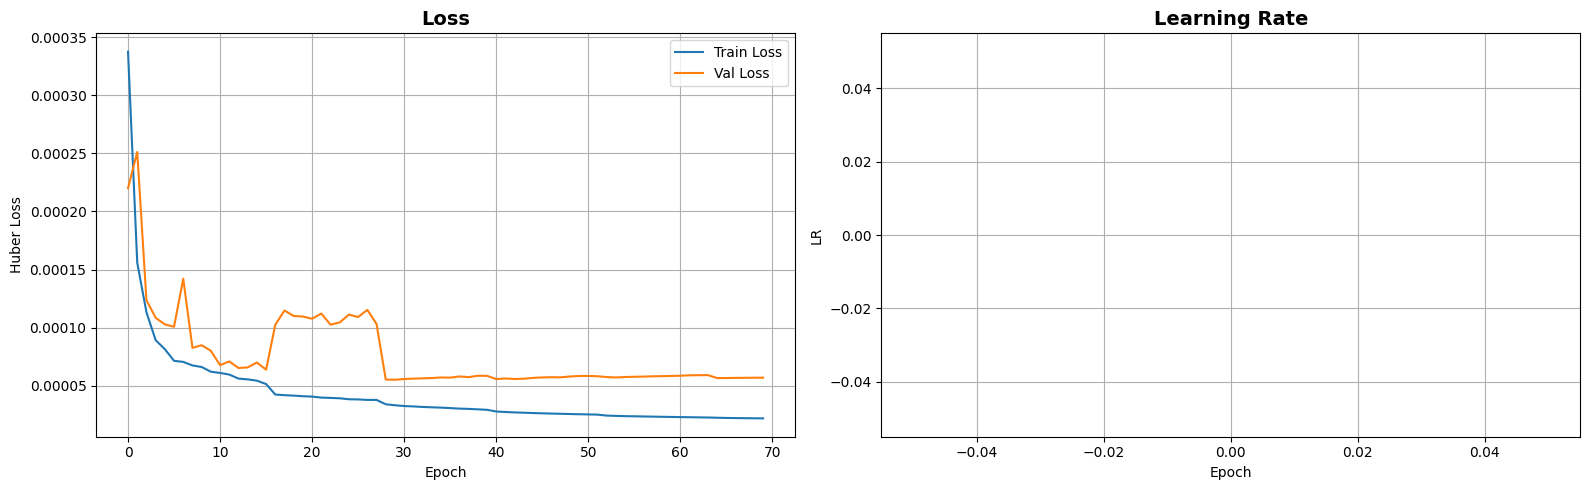

In [5]:
# Training history
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Val Loss')
axes[0].set_title('Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Huber Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['lr'] if 'lr' in history.history else [])
axes[1].set_title('Learning Rate', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('LR')
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'proposed_model_training.png'), dpi=150)
plt.show()

## 4. Evaluation

In [6]:
# Predict
y_pred = model.predict(X_test).flatten()
y_true_real = inverse_transform_target(y_test, scaler, TARGET_IDX, n_features)
y_pred_real = inverse_transform_target(y_pred, scaler, TARGET_IDX, n_features)

metrics = calculate_metrics(y_true_real, y_pred_real)
print('=== CNN-BiLSTM-Attention Results ===')
for k, v in metrics.items():
    print(f'  {k}: {v:.4f}')

# Save results
results_df = pd.DataFrame([metrics], index=['CNN-BiLSTM-Attention'])
results_df.to_csv(os.path.join(RESULTS_DIR, 'proposed_results.csv'))

np.savez_compressed(
    os.path.join(RESULTS_DIR, 'proposed_predictions.npz'),
    y_true=y_true_real, y_pred=y_pred_real
)


 1/80 ━━━━━━━━━━━━━━━━━━━━ 31s 401ms/step


 5/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step  


 9/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


13/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


17/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


21/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

... (12 outputs left out)


79/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step


=== CNN-BiLSTM-Attention Results ===
  MAE: 34.8514
  RMSE: 56.5212
  MAPE: 0.3714
  R2: 0.9884


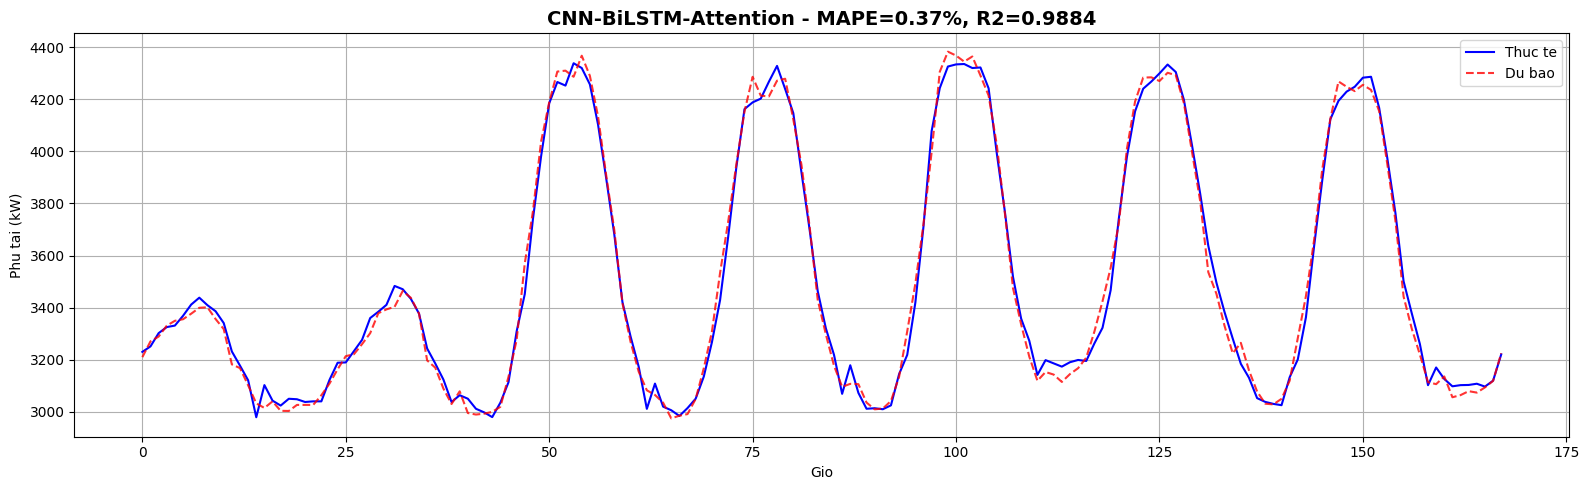

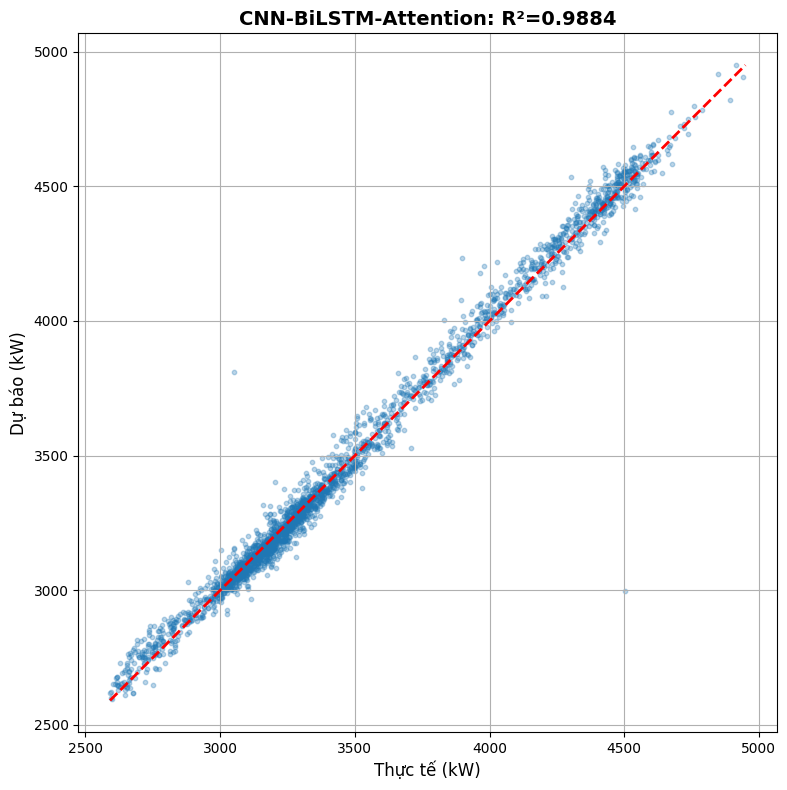

In [7]:
# Prediction plot
plot_predictions(y_true_real, y_pred_real, 'CNN-BiLSTM-Attention')

# Scatter plot
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_true_real, y_pred_real, alpha=0.3, s=10)
lims = [min(y_true_real.min(), y_pred_real.min()), max(y_true_real.max(), y_pred_real.max())]
ax.plot(lims, lims, 'r--', linewidth=2)
ax.set_xlabel('Actual (kW)', fontsize=12)
ax.set_ylabel('Forecast (kW)', fontsize=12)
ax.set_title(f'CNN-BiLSTM-Attention: R²={metrics["R2"]:.4f}', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'proposed_model_scatter.png'), dpi=150)
plt.show()

## 5. Attention Weights Visualization


1/4 ━━━━━━━━━━━━━━━━━━━━ 1s 477ms/step


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 170ms/step


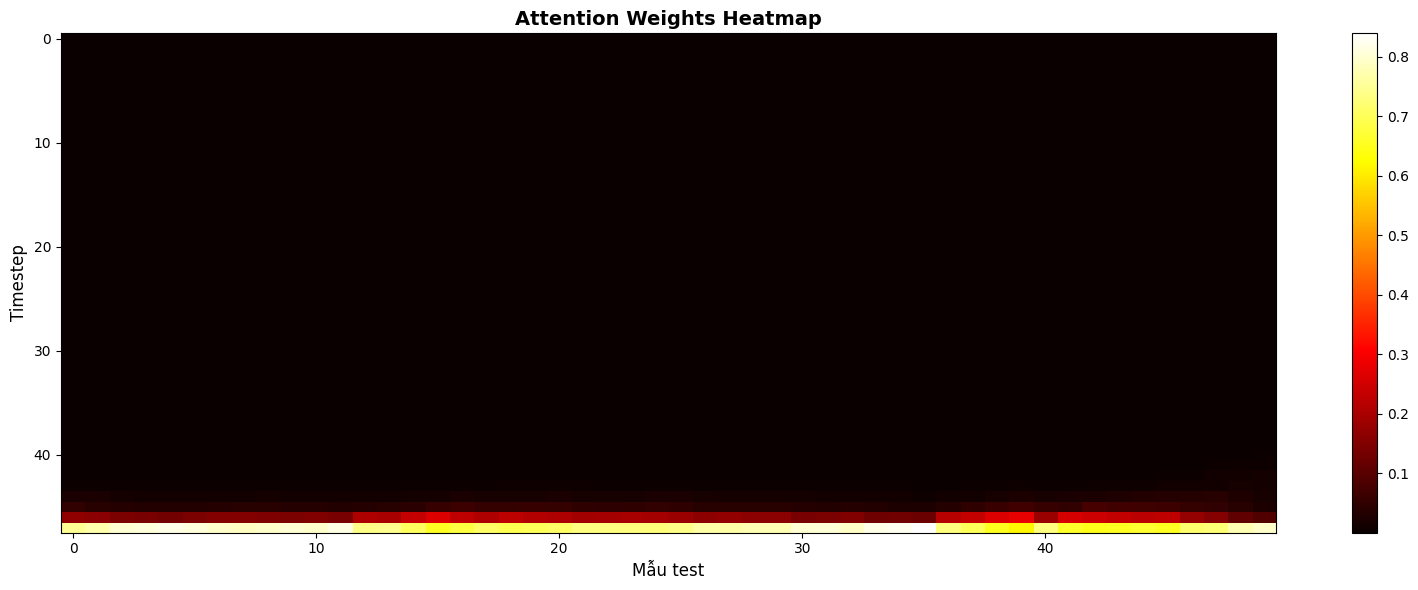

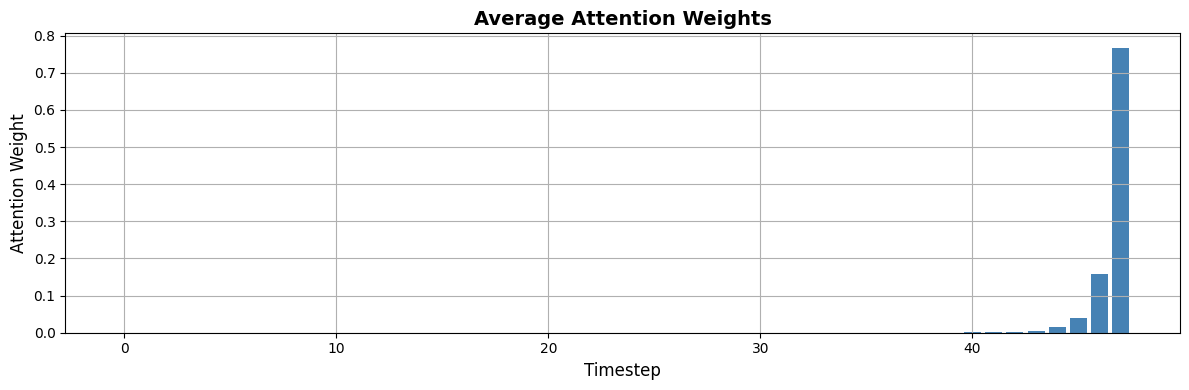


Notebook 04 hoàn tất! Tiếp theo: 05_Model_Comparison.ipynb


In [8]:
# Extract attention weights
attn_layer = None
for layer in model.layers:
    if isinstance(layer, AttentionLayer):
        attn_layer = layer
        break

if attn_layer:
    attn_model = Model(inputs=model.input, outputs=attn_layer.output[1])
    attn_weights = attn_model.predict(X_test[:100])

    # Heatmap
    fig, ax = plt.subplots(figsize=(16, 6))
    im = ax.imshow(attn_weights[:50].T, aspect='auto', cmap='hot')
    ax.set_xlabel('Test Sample', fontsize=12)
    ax.set_ylabel('Timestep', fontsize=12)
    ax.set_title('Attention Weights Heatmap', fontsize=14, fontweight='bold')
    plt.colorbar(im)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'attention_heatmap.png'), dpi=150)
    plt.show()

    # Average attention
    avg_attn = attn_weights.mean(axis=0)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(range(len(avg_attn)), avg_attn, color='steelblue')
    ax.set_xlabel('Timestep', fontsize=12)
    ax.set_ylabel('Attention Weight', fontsize=12)
    ax.set_title('Average Attention Weights', fontsize=14, fontweight='bold')
    ax.grid(True)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, 'attention_weights_avg.png'), dpi=150)
    plt.show()
else:
    print('Attention layer not found')

print('\nNotebook 04 hoàn tất! Tiếp theo: 05_Model_Comparison.ipynb')